# Neural Network (feed-forward, PyTorch)

**Idea:** the input goes through layers of neurons.
Each layer does `output = activation(W · input + b)`. The last layer gives one score per class. The class with the highest score is the prediction.

**Training:** we show the network small groups of examples (batches). For each batch:
1. **forward pass** – compute the scores
2. **loss** – cross-entropy: how wrong the scores are
3. **backward pass** – compute how each weight changes the loss (gradients)
4. **update** – move every weight a small step to reduce the loss (optimizer: Adam or SGD)

One pass over all training data = one **epoch**.

**Early stopping:** after each epoch we check validation accuracy. If it has not improved for `patience` epochs, we stop and keep the best weights. This limits overfitting.

We change **one hyperparameter at a time** and keep the rest fixed (the baseline).

## 1. Setup

In [1]:
import os
import sys

# The notebook is in a sub-folder. Go to the project folder (where common.py is).
if not os.path.exists("common.py"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Some Windows installs crash when NumPy and PyTorch both load OpenMP. This line avoids it.
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import torch
import torch.nn as nn

import common   # our shared file: load data, split, metrics, Kaggle file

common.set_seed(42)
os.makedirs("neural_network/outputs", exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| running on", device)

PyTorch 2.15.0+cpu | running on cpu


## 2. Load the data

Same 80% train / 20% validation split as every model of the team.

In [2]:
X_image, y_image, X_image_test, image_test_ids = common.load_task("image")
X_sent, y_sent, X_sent_test, sent_test_ids = common.load_task("sentiment")

DATA = {"image": (X_image, y_image), "sentiment": (X_sent, y_sent)}
TEST = {"image": (X_image_test, image_test_ids), "sentiment": (X_sent_test, sent_test_ids)}
N_CLASSES = common.N_CLASSES    # {"image": 50, "sentiment": 3}


def prepare(task, preprocess):
    """Split into train / validation, then apply the preprocessing (statistics from train rows only)."""
    X, y = DATA[task]
    train_idx, val_idx = common.stratified_split(y)
    stats = common.fit_preprocessing(X[train_idx], preprocess)
    X_train = common.apply_preprocessing(X[train_idx], preprocess, stats)
    X_val = common.apply_preprocessing(X[val_idx], preprocess, stats)
    return X_train, y[train_idx], X_val, y[val_idx]


print("image:", X_image.shape, "| sentiment:", X_sent.shape)

image: (20000, 500) | sentiment: (12000, 768)


## 3. The network

`hidden_sizes` is the list of hidden layers. Examples:
* `[]` – no hidden layer: input → output (a linear model)
* `[256]` – one hidden layer with 256 neurons
* `[256, 64]` – two hidden layers

**Dropout:** during training, randomly set some values to 0. The network cannot rely on a few neurons, so it overfits less.
`input_dropout` does the same on the input features.

In [3]:
ACTIVATIONS = {"relu": nn.ReLU, "tanh": nn.Tanh, "sigmoid": nn.Sigmoid}


class Network(nn.Module):
    def __init__(self, n_inputs, n_outputs, hidden_sizes, activation="relu", dropout=0.0, input_dropout=0.0):
        super().__init__()
        layers = []
        if input_dropout > 0:
            layers.append(nn.Dropout(input_dropout))

        size = n_inputs
        for hidden in hidden_sizes:
            layers.append(nn.Linear(size, hidden))        # W · x + b
            layers.append(ACTIVATIONS[activation]())      # activation function
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            size = hidden

        layers.append(nn.Linear(size, n_outputs))         # output layer: one score per class
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(x)


# Example: the network from the project description
example = Network(n_inputs=500, n_outputs=50, hidden_sizes=[256, 64])
print(example)
print("number of weights:", sum(p.numel() for p in example.parameters()))

Network(
  (layers): Sequential(
    (0): Linear(in_features=500, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=50, bias=True)
  )
)
number of weights: 147954


## 4. Training loop

* **Adam** – changes the step size for every weight by itself. Usually works well without much tuning.
* **SGD with momentum** – the classic method. Needs a bigger learning rate.
* **weight_decay** – pushes weights towards 0 (another way to limit overfitting).

In [4]:
def make_optimizer(model, s):
    if s["optimizer"] == "adam":
        return torch.optim.AdamW(model.parameters(), lr=s["lr"], weight_decay=s["weight_decay"])
    return torch.optim.SGD(model.parameters(), lr=s["lr"], momentum=0.9, weight_decay=s["weight_decay"])


def train_one_epoch(model, optimizer, loss_function, X, y, batch_size):
    model.train()                                       # dropout ON
    order = torch.randperm(len(X), device=device)       # new random order every epoch
    for start in range(0, len(X), batch_size):
        batch = order[start:start + batch_size]
        scores = model(X[batch])                        # 1. forward pass
        loss = loss_function(scores, y[batch])          # 2. loss
        optimizer.zero_grad()
        loss.backward()                                 # 3. backward pass
        optimizer.step()                                # 4. update the weights


def accuracy_of(model, X, y):
    model.eval()                                        # dropout OFF
    with torch.no_grad():
        return (model(X).argmax(dim=1) == y).float().mean().item()


def train(task, s, seed=42):
    """Train with early stopping. Returns the model (best epoch weights) and the history."""
    common.set_seed(seed)
    X_tr, y_tr, X_va, y_va = prepare(task, s["preprocess"])
    X_tr, y_tr = torch.tensor(X_tr).to(device), torch.tensor(y_tr).to(device)
    X_va, y_va = torch.tensor(X_va).to(device), torch.tensor(y_va).to(device)

    model = Network(X_tr.shape[1], N_CLASSES[task], s["hidden_sizes"], s["activation"],
                    s["dropout"], s["input_dropout"]).to(device)
    optimizer = make_optimizer(model, s)
    loss_function = nn.CrossEntropyLoss()

    history = {"train_acc": [], "val_acc": []}
    best_val, best_epoch, best_weights = 0.0, 0, None
    for epoch in range(1, s["max_epochs"] + 1):
        train_one_epoch(model, optimizer, loss_function, X_tr, y_tr, s["batch_size"])
        history["train_acc"].append(accuracy_of(model, X_tr, y_tr))
        history["val_acc"].append(accuracy_of(model, X_va, y_va))

        if history["val_acc"][-1] > best_val:                        # new best epoch
            best_val, best_epoch = history["val_acc"][-1], epoch
            best_weights = {k: v.clone() for k, v in model.state_dict().items()}
        elif epoch - best_epoch >= s["patience"]:                    # no progress: stop
            break

    model.load_state_dict(best_weights)
    history["best_epoch"] = best_epoch
    return model, history


def plot_history(history, title):
    plt.figure(figsize=(6, 3.5))
    plt.plot(history["train_acc"], label="train")
    plt.plot(history["val_acc"], label="validation")
    plt.axvline(history["best_epoch"] - 1, color="gray", linestyle="--", label="best epoch")
    plt.xlabel("epoch")
    plt.ylabel("accuracy")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

## 5. Experiment helper

`run_experiment` starts from the baseline, changes **one** hyperparameter, trains, and prints train and validation accuracy.
A big gap between train and validation = overfitting.

In [5]:
results = []
best_runs = {}     # task -> the best run so far (accuracy, settings, model, best epoch)


def run_one(task, name, value, settings):
    start = time.time()
    model, history = train(task, settings)
    best = history["best_epoch"] - 1
    row = {"task": task, "hyperparameter": name, "value": str(value),
           "train_acc": round(history["train_acc"][best], 4),
           "val_acc": round(history["val_acc"][best], 4),
           "best_epoch": history["best_epoch"], "seconds": round(time.time() - start, 1)}
    results.append(row)
    print(f"{name} = {str(value):<18} train {row['train_acc']:.3f}   validation {row['val_acc']:.3f}"
          f"   best epoch {row['best_epoch']:3d}   ({row['seconds']}s)")
    if task not in best_runs or row["val_acc"] > best_runs[task]["val_acc"]:
        best_runs[task] = {"val_acc": row["val_acc"], "settings": settings,
                           "model": model, "best_epoch": history["best_epoch"]}
    return row


def run_experiment(task, baseline, name, values):
    rows = []
    for value in values:
        settings = dict(baseline)
        settings[name] = value                 # change ONE hyperparameter
        rows.append(run_one(task, name, value, settings))
    # bar chart: train vs validation
    x = np.arange(len(rows))
    plt.figure(figsize=(6, 3))
    plt.bar(x - 0.2, [r["train_acc"] for r in rows], width=0.4, label="train")
    plt.bar(x + 0.2, [r["val_acc"] for r in rows], width=0.4, label="validation")
    plt.xticks(x, [r["value"] for r in rows])
    plt.ylim(0, 1)
    plt.title(f"{task}: {name}")
    plt.legend()
    plt.show()

## 6. Sentiment task (3 classes)

### 6.1 Baseline

best epoch 40 | validation accuracy 0.6804


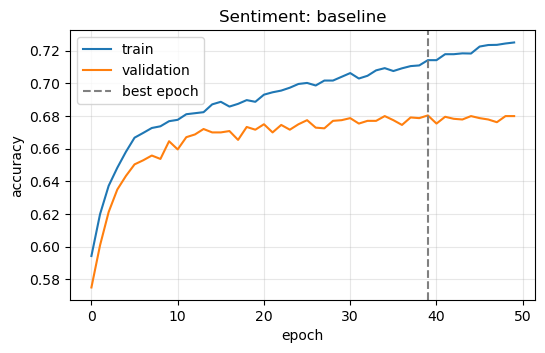

In [6]:
SENT_BASELINE = {
    "preprocess": "none",
    "hidden_sizes": [256],
    "activation": "relu",
    "dropout": 0.5,
    "input_dropout": 0.2,
    "optimizer": "adam",
    "lr": 1e-4,              # learning rate
    "weight_decay": 1e-2,
    "batch_size": 128,
    "max_epochs": 100,
    "patience": 10,          # early stopping
}

model, history = train("sentiment", SENT_BASELINE)
print("best epoch", history["best_epoch"], "| validation accuracy", round(max(history["val_acc"]), 4))
plot_history(history, "Sentiment: baseline")

### 6.2 One hyperparameter at a time

preprocess = none               train 0.714   validation 0.680   best epoch  40   (18.8s)
preprocess = standardize        train 0.750   validation 0.681   best epoch  15   (9.2s)


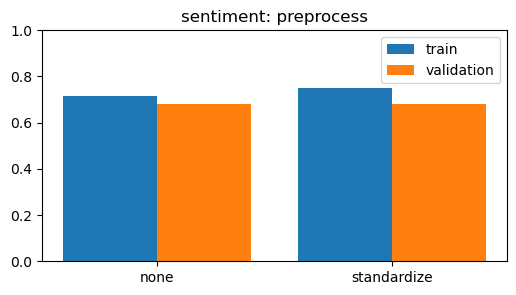

In [7]:
run_experiment("sentiment", SENT_BASELINE, "preprocess", ["none", "standardize"])

hidden_sizes = []                 train 0.680   validation 0.667   best epoch  58   (13.3s)
hidden_sizes = [64]               train 0.685   validation 0.674   best epoch  26   (10.3s)
hidden_sizes = [256]              train 0.714   validation 0.680   best epoch  40   (19.4s)
hidden_sizes = [256, 64]          train 0.740   validation 0.687   best epoch  53   (28.5s)


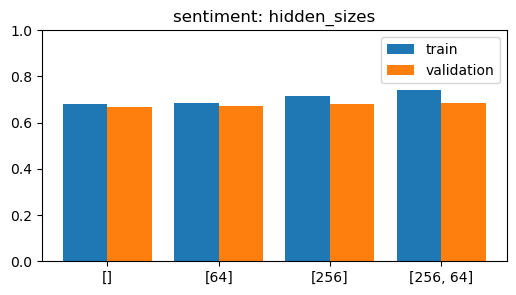

In [8]:
run_experiment("sentiment", SENT_BASELINE, "hidden_sizes", [[], [64], [256], [256, 64]])

activation = relu               train 0.714   validation 0.680   best epoch  40   (18.7s)
activation = tanh               train 0.699   validation 0.677   best epoch  28   (14.2s)
activation = sigmoid            train 0.682   validation 0.673   best epoch  47   (20.6s)


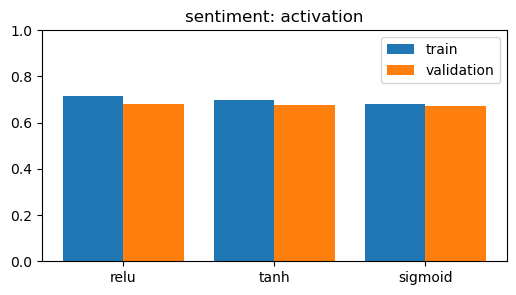

In [9]:
run_experiment("sentiment", SENT_BASELINE, "activation", ["relu", "tanh", "sigmoid"])

dropout = 0.0                train 0.705   validation 0.680   best epoch  26   (12.5s)
dropout = 0.2                train 0.719   validation 0.681   best epoch  38   (17.5s)
dropout = 0.5                train 0.714   validation 0.680   best epoch  40   (18.4s)


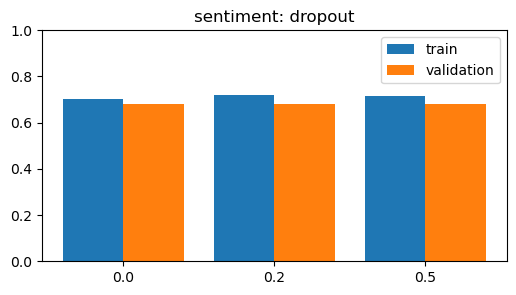

In [10]:
run_experiment("sentiment", SENT_BASELINE, "dropout", [0.0, 0.2, 0.5])

lr = 0.01               train 0.698   validation 0.670   best epoch   9   (10.1s)
lr = 0.001              train 0.717   validation 0.685   best epoch  10   (8.3s)
lr = 0.0001             train 0.714   validation 0.680   best epoch  40   (18.4s)


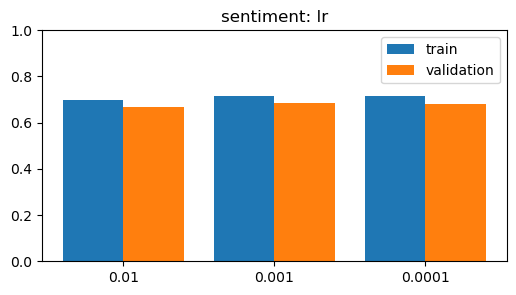

In [11]:
run_experiment("sentiment", SENT_BASELINE, "lr", [1e-2, 1e-3, 1e-4])

batch_size = 32                 train 0.707   validation 0.679   best epoch  19   (27.2s)
batch_size = 128                train 0.714   validation 0.680   best epoch  40   (18.4s)
batch_size = 512                train 0.690   validation 0.675   best epoch  36   (10.8s)


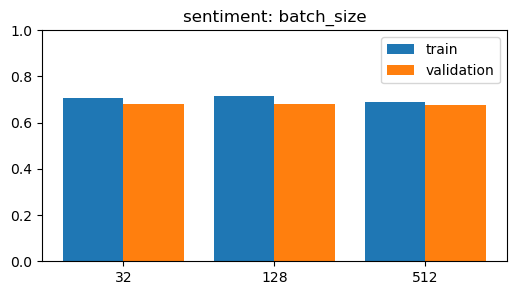

In [12]:
run_experiment("sentiment", SENT_BASELINE, "batch_size", [32, 128, 512])

In [13]:
# SGD needs a bigger learning rate than Adam, so we give it 0.01
run_one("sentiment", "optimizer", "sgd (lr 0.01)", {**SENT_BASELINE, "optimizer": "sgd", "lr": 1e-2})

optimizer = sgd (lr 0.01)      train 0.693   validation 0.678   best epoch  26   (15.8s)


{'task': 'sentiment',
 'hyperparameter': 'optimizer',
 'value': 'sgd (lr 0.01)',
 'train_acc': 0.6934,
 'val_acc': 0.6783,
 'best_epoch': 26,
 'seconds': 15.8}

## 7. Image task (50 classes)

### 7.1 Baseline

best epoch 100 | validation accuracy 0.4527


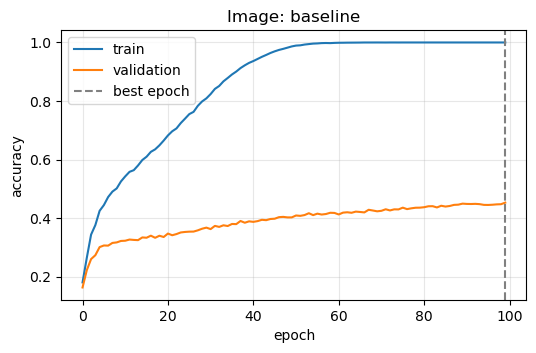

In [14]:
IMAGE_BASELINE = {
    "preprocess": "none",
    "hidden_sizes": [1024],
    "activation": "relu",
    "dropout": 0.2,
    "input_dropout": 0.2,
    "optimizer": "adam",
    "lr": 1e-3,
    "weight_decay": 1e-2,
    "batch_size": 128,
    "max_epochs": 100,
    "patience": 10,
}

model, history = train("image", IMAGE_BASELINE)
print("best epoch", history["best_epoch"], "| validation accuracy", round(max(history["val_acc"]), 4))
plot_history(history, "Image: baseline")

### 7.2 One hyperparameter at a time

preprocess = none               train 1.000   validation 0.453   best epoch 100   (496.3s)
preprocess = standardize        train 1.000   validation 0.408   best epoch  34   (152.2s)
preprocess = sqrt               train 1.000   validation 0.440   best epoch 100   (429.8s)


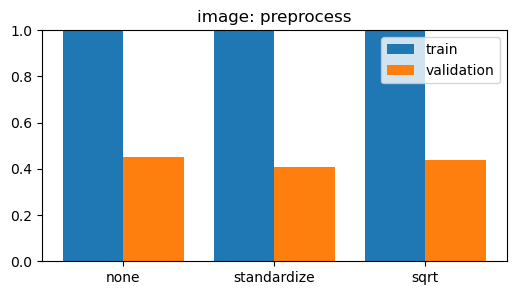

In [15]:
run_experiment("image", IMAGE_BASELINE, "preprocess", ["none", "standardize", "sqrt"])

hidden_sizes = []                 train 0.486   validation 0.316   best epoch  78   (100.6s)
hidden_sizes = [256]              train 0.520   validation 0.327   best epoch  21   (64.4s)
hidden_sizes = [1024]             train 1.000   validation 0.453   best epoch 100   (453.1s)
hidden_sizes = [1024, 256]        train 0.999   validation 0.430   best epoch  33   (345.4s)


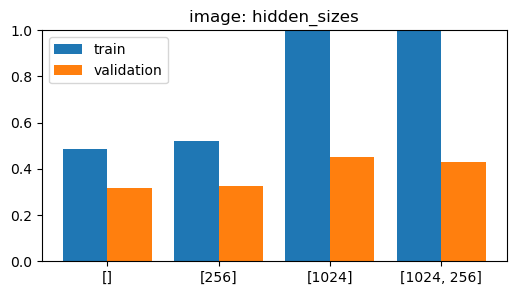

In [16]:
run_experiment("image", IMAGE_BASELINE, "hidden_sizes", [[], [256], [1024], [1024, 256]])

activation = relu               train 1.000   validation 0.453   best epoch 100   (532.2s)
activation = tanh               train 0.510   validation 0.317   best epoch   9   (101.0s)
activation = sigmoid            train 0.501   validation 0.319   best epoch  46   (298.3s)


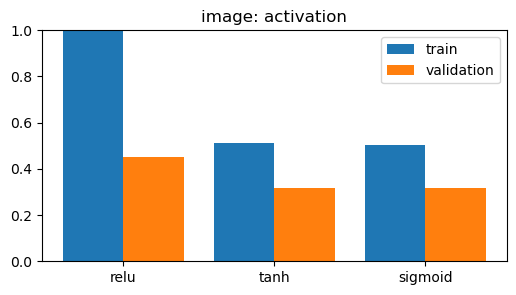

In [17]:
run_experiment("image", IMAGE_BASELINE, "activation", ["relu", "tanh", "sigmoid"])

dropout = 0.0                train 1.000   validation 0.457   best epoch  98   (385.4s)
dropout = 0.2                train 1.000   validation 0.453   best epoch 100   (432.4s)
dropout = 0.5                train 1.000   validation 0.431   best epoch  98   (484.4s)


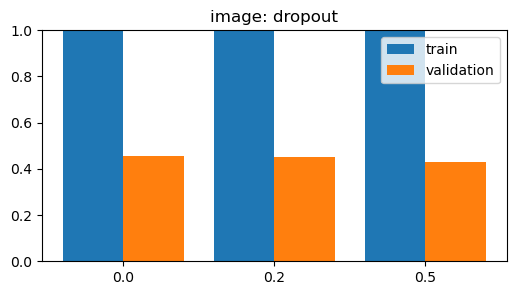

In [18]:
run_experiment("image", IMAGE_BASELINE, "dropout", [0.0, 0.2, 0.5])

lr = 0.01               train 0.999   validation 0.421   best epoch  15   (162.4s)
lr = 0.001              train 1.000   validation 0.453   best epoch 100   (553.1s)
lr = 0.0001             train 0.507   validation 0.324   best epoch  98   (459.9s)


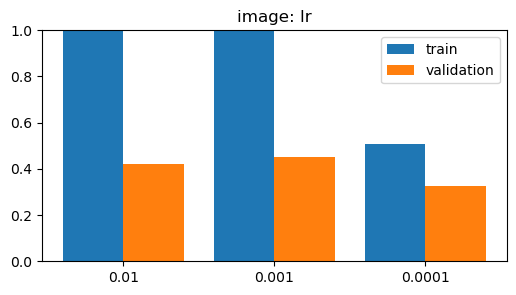

In [19]:
run_experiment("image", IMAGE_BASELINE, "lr", [1e-2, 1e-3, 1e-4])

batch_size = 32                 train 1.000   validation 0.454   best epoch  57   (672.4s)
batch_size = 128                train 1.000   validation 0.453   best epoch 100   (504.3s)
batch_size = 512                train 0.973   validation 0.396   best epoch 100   (295.4s)


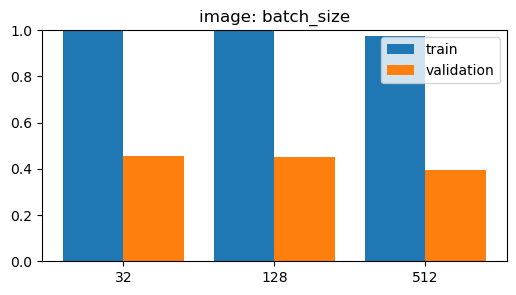

In [20]:
run_experiment("image", IMAGE_BASELINE, "batch_size", [32, 128, 512])

In [21]:
run_one("image", "optimizer", "sgd (lr 0.01)", {**IMAGE_BASELINE, "optimizer": "sgd", "lr": 1e-2})

optimizer = sgd (lr 0.01)      train 0.143   validation 0.119   best epoch  10   (98.5s)


{'task': 'image',
 'hyperparameter': 'optimizer',
 'value': 'sgd (lr 0.01)',
 'train_acc': 0.1429,
 'val_acc': 0.1187,
 'best_epoch': 10,
 'seconds': 98.5}

## 8. All results

In [22]:
table = pd.DataFrame(results)
table["gap"] = (table["train_acc"] - table["val_acc"]).round(4)     # big gap = overfitting
for task in ["sentiment", "image"]:
    t = table[table["task"] == task].sort_values("val_acc", ascending=False)
    t.to_csv(f"neural_network/outputs/{task}_experiments.csv", index=False)
    display(t)

,task,hyperparameter,value,train_acc,val_acc,best_epoch,seconds,gap
5,sentiment,hidden_sizes,"[256, 64]",0.7395,0.6867,53,28.5,0.0528
13,sentiment,lr,0.001,0.7170,0.6846,10,8.3,0.0324
10,sentiment,dropout,0.2,0.7188,0.6812,38,17.5,0.0376
1,sentiment,preprocess,standardize,0.7502,0.6812,15,9.2,0.0690
0,sentiment,preprocess,none,0.7143,0.6804,40,18.8,0.0339
16,sentiment,batch_size,128,0.7143,0.6804,40,18.4,0.0339
14,sentiment,lr,0.0001,0.7143,0.6804,40,18.4,0.0339
4,sentiment,hidden_sizes,[256],0.7143,0.6804,40,19.4,0.0339
6,sentiment,activation,relu,0.7143,0.6804,40,18.7,0.0339
11,sentiment,dropout,0.5,0.7143,0.6804,40,18.4,0.0339


,task,hyperparameter,value,train_acc,val_acc,best_epoch,seconds,gap
29,image,dropout,0.0,1.0000,0.4568,98,385.4,0.5432
35,image,batch_size,32,1.0000,0.4538,57,672.4,0.5462
26,image,activation,relu,1.0000,0.4527,100,532.2,0.5473
36,image,batch_size,128,1.0000,0.4527,100,504.3,0.5473
33,image,lr,0.001,1.0000,0.4527,100,553.1,0.5473
30,image,dropout,0.2,1.0000,0.4527,100,432.4,0.5473
19,image,preprocess,none,1.0000,0.4527,100,496.3,0.5473
24,image,hidden_sizes,[1024],1.0000,0.4527,100,453.1,0.5473
21,image,preprocess,sqrt,1.0000,0.4403,100,429.8,0.5597
31,image,dropout,0.5,0.9999,0.4310,98,484.4,0.5689


## 9. Best network: error analysis

For each task we keep the run with the best validation accuracy.

sentiment best settings: {'preprocess': 'none', 'hidden_sizes': [256, 64], 'activation': 'relu', 'dropout': 0.5, 'input_dropout': 0.2, 'optimizer': 'adam', 'lr': 0.0001, 'weight_decay': 0.01, 'batch_size': 128, 'max_epochs': 100, 'patience': 10}
validation accuracy 0.6867


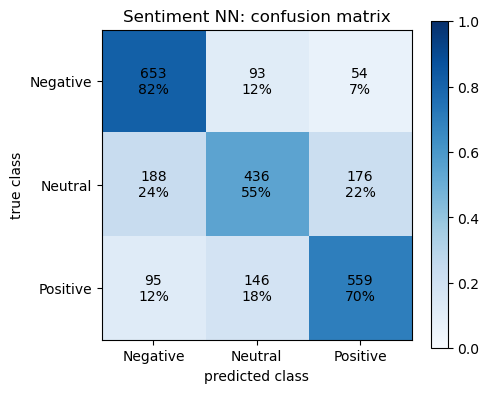

   Negative  recall 0.816   precision 0.698
   Neutral   recall 0.545   precision 0.646
   Positive  recall 0.699   precision 0.708
image best settings: {'preprocess': 'none', 'hidden_sizes': [1024], 'activation': 'relu', 'dropout': 0.0, 'input_dropout': 0.2, 'optimizer': 'adam', 'lr': 0.001, 'weight_decay': 0.01, 'batch_size': 128, 'max_epochs': 100, 'patience': 10}
validation accuracy 0.4567


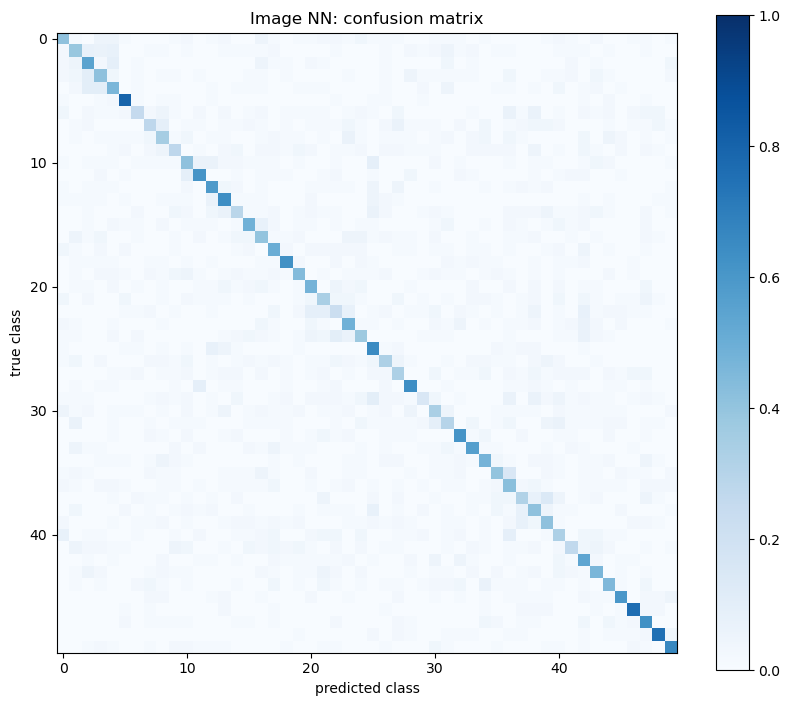

   most common mistakes (true class, predicted class, count):
      35 -> 36   12 times
      37 -> 39   11 times
       3 ->  2   8 times
       4 ->  2   8 times
       4 ->  3   8 times
      24 -> 22   8 times
      29 -> 25   8 times
       2 ->  4   7 times
       7 ->  8   7 times
      10 -> 25   7 times


In [23]:
def plot_confusion(cm, title, labels=None):
    shares = cm / cm.sum(axis=1, keepdims=True)
    size = 5 if len(cm) <= 3 else 10
    plt.figure(figsize=(size, size * 0.85))
    plt.imshow(shares, cmap="Blues", vmin=0, vmax=1)
    plt.colorbar()
    if labels is not None:
        plt.xticks(range(len(labels)), labels)
        plt.yticks(range(len(labels)), labels)
        for i in range(len(cm)):
            for j in range(len(cm)):
                plt.text(j, i, f"{cm[i, j]}\n{shares[i, j]:.0%}", ha="center", va="center")
    plt.xlabel("predicted class")
    plt.ylabel("true class")
    plt.title(title)
    plt.show()


for task in ["sentiment", "image"]:
    run = best_runs[task]
    print(task, "best settings:", run["settings"])
    _, _, X_va, y_va = prepare(task, run["settings"]["preprocess"])
    run["model"].eval()
    with torch.no_grad():
        pred = run["model"](torch.tensor(X_va).to(device)).argmax(dim=1).cpu().numpy()
    np.save(f"neural_network/outputs/{task}_val_pred.npy", pred)     # used by final/compare.ipynb
    print(f"validation accuracy {common.accuracy(y_va, pred):.4f}")

    cm = common.confusion_matrix(y_va, pred, N_CLASSES[task])
    if task == "sentiment":
        plot_confusion(cm, "Sentiment NN: confusion matrix", common.SENTIMENT_NAMES)
        recall = common.per_class_recall(cm)
        precision = common.per_class_precision(cm)
        for i, name in enumerate(common.SENTIMENT_NAMES):
            print(f"   {name:<9} recall {recall[i]:.3f}   precision {precision[i]:.3f}")
    else:
        plot_confusion(cm, "Image NN: confusion matrix")
        print("   most common mistakes (true class, predicted class, count):")
        for true_c, pred_c, count in common.most_confused_pairs(cm, 10):
            print(f"      {true_c:2d} -> {pred_c:2d}   {count} times")

## 10. Test predictions for Kaggle

We train the best network again on **all** training rows. There is no validation set left for early stopping, so we train for the same number of epochs as the best epoch found above.

In [24]:
def train_final(task, s, n_epochs, seed=42):
    common.set_seed(seed)
    X, y = DATA[task]
    X_test, test_ids = TEST[task]
    stats = common.fit_preprocessing(X, s["preprocess"])
    X_all = torch.tensor(common.apply_preprocessing(X, s["preprocess"], stats)).to(device)
    y_all = torch.tensor(y).to(device)
    X_test = torch.tensor(common.apply_preprocessing(X_test, s["preprocess"], stats)).to(device)

    model = Network(X_all.shape[1], N_CLASSES[task], s["hidden_sizes"], s["activation"],
                    s["dropout"], s["input_dropout"]).to(device)
    optimizer = make_optimizer(model, s)
    loss_function = nn.CrossEntropyLoss()
    for epoch in range(n_epochs):
        train_one_epoch(model, optimizer, loss_function, X_all, y_all, s["batch_size"])

    model.eval()
    with torch.no_grad():
        return model(X_test).argmax(dim=1).cpu().numpy(), test_ids


for task in ["sentiment", "image"]:
    run = best_runs[task]
    pred, test_ids = train_final(task, run["settings"], run["best_epoch"])
    pd.DataFrame({"id": test_ids, "label": pred}).to_csv(f"neural_network/outputs/{task}_test_pred.csv", index=False)
    print(f"{task}: saved neural_network/outputs/{task}_test_pred.csv ({run['best_epoch']} epochs)")

sentiment: saved neural_network/outputs/sentiment_test_pred.csv (53 epochs)
image: saved neural_network/outputs/image_test_pred.csv (98 epochs)
